## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [3]:
#VERSION 1: DECODER ONLY MODEL; using GQA+ROPE+RMSNORM

import os
import random
import json
import time
import math
import zipfile
import shutil
import torch
import numpy as np

SEED =42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Basic setup loaded.")
print(f"Random seed: {SEED}")

Basic setup loaded.
Random seed: 42


In [4]:
#DATASET
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

#for this version i am using just the supreme court training files
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE ="Phase_1_Pretraining/Test/test.json"

#for this version i was not sure of the computation timing so taking just 100M tokens
TRAIN_TOKENS = 100_000_000
VAL_TOKENS = 5_000_000

print("Dataset settings loaded.")
print("Training file:", TRAIN_FILE)
print("Training tokens:", f"{TRAIN_TOKENS:,}")
print("Validation tokens:", f"{VAL_TOKENS:,}")

Dataset settings loaded.
Training file: Phase_1_Pretraining/Train/train_supreme_court.json
Training tokens: 100,000,000
Validation tokens: 5,000,000


In [5]:
#context length basically tells us about how many tokens it can look at in one traing example
MODEL_CONTEXT_LENGTH=1024
TRAIN_BLOCK_SIZE = MODEL_CONTEXT_LENGTH
print("CL:", MODEL_CONTEXT_LENGTH)
print("Training block size:", TRAIN_BLOCK_SIZE)

CL: 1024
Training block size: 1024


In [6]:
#ARCHITECTURE
#Using 12 layers for a deeper model
N_LAYER=12
N_EMBD=768 #every token will be represented using 768 numbers inside the model
N_HEAD=12

#Number of key/value heads
#12 query heads will share 4 key heads and 4 value heads
N_KV_HEAD=4

#using normal feed-forward network
FFN_MULTIPLIER=4
DROPOUT=0.0
USE_ROPE= True
USE_RMSNORM = True

#sanity check
print("Model architecture settings loaded.")
print(f"Layers: {N_LAYER}")
print(f"Hidden size: {N_EMBD}")
print(f"Query heads: {N_HEAD}")
print(f"Key/Value heads: {N_KV_HEAD}")

Model architecture settings loaded.
Layers: 12
Hidden size: 768
Query heads: 12
Key/Value heads: 4


In [7]:
#TRAINING SETTINGS
PER_DEVICE_BATCH_SIZE=4
#To avoid any error as GPU might not be able to fit the large batch directly
GRADIENT_ACCUMULATION_STEPS=8
LEARNING_RATE = 3e-4
WEIGHT_DECAY=0.1
WARMUP_STEPS=500          #The learning rate inreases slowly instead of immediately using the entire value from start
MAX_GRAD_NORM=1000
EVAL_EVERY_STEPS=1000        #validation loss check frequency
LOG_EVERY_STEPS=100    #Print frequency
SAVE_EVERY_STEPS=1000
MAX_CHECKPOINTS_TO_KEEP=5
USE_AMP =torch.cuda.is_available()
USE_GRADIENT_CHECKPOINTING = False

#sanity check
print("Training settings loaded.")
print("Batch size:", PER_DEVICE_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Effective batch size:",PER_DEVICE_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Learning rate:", LEARNING_RATE)

Training settings loaded.
Batch size: 4
Gradient accumulation: 8
Effective batch size: 32
Learning rate: 0.0003


In [8]:
#Generation and output settings

TARGET_GENERATION_WORDS=128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7            #The starter uses 0.1, but its predictions showed strong repetition, so i am experimenting it
TOP_P =0.95
TOP_K=50 #adding this as an experiment
REPETITION_PENALTY=1.1 #Adding a penalty as the predictions showed heavy repetition

#OUTPUT and CHECKPOINT PATHS

OUTPUT_DIR = "/kaggle/working/cs781_phase1_v1"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
CACHE_DIR = os.path.join(OUTPUT_DIR, "cache")
LOG_DIR = os.path.join(OUTPUT_DIR, "logs")
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "final_model")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
CONFIG_PATH = os.path.join(OUTPUT_DIR, "config.json")

for directory in[
    OUTPUT_DIR,CHECKPOINT_DIR,CACHE_DIR,LOG_DIR,MODEL_OUTPUT_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("Generation and output settings loaded.")
print("Output directory:", OUTPUT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Cache directory:", CACHE_DIR)

Generation and output settings loaded.
Output directory: /kaggle/working/cs781_phase1_v1
Checkpoint directory: /kaggle/working/cs781_phase1_v1/checkpoints
Cache directory: /kaggle/working/cs781_phase1_v1/cache


In [9]:
#Experiment configuration
#this is to keep a track of my experiments and implemntations so that they donot mix up with the future ones

experiment_config = {
    "seed": SEED,

    # Dataset
    "dataset": HF_DATASET_REPO,
    "train_file": TRAIN_FILE,
    "train_tokens": TRAIN_TOKENS,
    "val_tokens": VAL_TOKENS,

    # Sequence length
    "context_length": MODEL_CONTEXT_LENGTH,
    "block_size": TRAIN_BLOCK_SIZE,

    # Model architecture
    "n_layer": N_LAYER,
    "n_embd": N_EMBD,
    "n_head": N_HEAD,
    "n_kv_head": N_KV_HEAD,
    "ffn_multiplier": FFN_MULTIPLIER,
    "dropout": DROPOUT,
    "use_rope": USE_ROPE,
    "use_rmsnorm": USE_RMSNORM,

    # Training
    "batch_size": PER_DEVICE_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_steps": WARMUP_STEPS,
    "max_grad_norm": MAX_GRAD_NORM,
    "eval_every_steps": EVAL_EVERY_STEPS,
    "log_every_steps": LOG_EVERY_STEPS,
    "save_every_steps": SAVE_EVERY_STEPS,
    "max_checkpoints_to_keep": MAX_CHECKPOINTS_TO_KEEP,
    "use_amp": USE_AMP,

    # Generation
    "target_generation_words": TARGET_GENERATION_WORDS,
    "max_generation_tokens": MAX_GENERATION_TOKENS,
    "temperature": TEMPERATURE,
    "top_p": TOP_P,
    "top_k": TOP_K,
    "repetition_penalty": REPETITION_PENALTY,
}

## 4. Load Tokenizer

In [10]:
#tokenizer from A1
import os
import json

BPE_FILENAME = "bpe_en_25k.json"
bpe_candidates = []

for root, dirs, files in os.walk("/kaggle/input"):
    if BPE_FILENAME in files:
        bpe_candidates.append(os.path.join(root, BPE_FILENAME))

if len(bpe_candidates) == 0:
    raise FileNotFoundError(
        f"{BPE_FILENAME} was not found inside /kaggle/input/. "
        "Make sure the BPE-25k dataset is attached."
    )

BPE_PATH = bpe_candidates[0]

print("Tokenizer found:", BPE_PATH)


# Load the vocabulary and learned BPE merges.
with open(BPE_PATH, "r", encoding="utf-8") as f:
    bpe_data = json.load(f)

bpe_itos = bpe_data["itos"]
bpe_merges = bpe_data["merges"]
bpe_vocab_size = bpe_data["vocab_size"]

# Make sure we have loaded the tokenizer we actually want.
assert bpe_vocab_size == 25_000
assert len(bpe_itos) == 25_000

print("Vocabulary size:", bpe_vocab_size)
print("Number of merge rules:", len(bpe_merges))


# Token -> ID mapping
bpe_stoi = {
    token: idx
    for idx, token in enumerate(bpe_itos)
}
merge_to_id = {}

for merge_index, merge in enumerate(bpe_merges):
    left_token, right_token = merge

    left_id = bpe_stoi[left_token]
    right_id = bpe_stoi[right_token]

    new_token_id = 261 + merge_index
    merge_to_id[(left_id, right_id)] = new_token_id

PAD_TOKEN_ID = bpe_stoi["<pad>"]
UNK_TOKEN_ID = bpe_stoi["<unk>"]
BOS_TOKEN_ID = bpe_stoi["<s>"]
EOS_TOKEN_ID = bpe_stoi["</s>"]
WORD_BOUNDARY_ID = bpe_stoi["<wb>"]

print("\nSpecial token IDs:")
print("PAD:", PAD_TOKEN_ID)
print("UNK:", UNK_TOKEN_ID)
print("BOS:", BOS_TOKEN_ID)
print("EOS:", EOS_TOKEN_ID)
print("WORD BOUNDARY:", WORD_BOUNDARY_ID)

Tokenizer found: /kaggle/input/datasets/ayushbunnumaharaj/v1-bpe-25k/bpe_en_25k.json
Vocabulary size: 25000
Number of merge rules: 24739

Special token IDs:
PAD: 0
UNK: 1
BOS: 2
EOS: 3
WORD BOUNDARY: 260


In [11]:
#Tokenizer Sanity Check
#Before using the tokenizer on the full legal corpus,let's check a small example and make sure encoding and decoding work correctly.

class ByteLevelBPE25k:
    def __init__(self, itos, stoi, merge_to_id, merges):
        self.itos = itos
        self.stoi = stoi
        self.merge_to_id = merge_to_id
        self.merges = merges
        self.vocab_size = len(itos)

        self.pad_token_id = stoi["<pad>"]
        self.unk_token_id = stoi["<unk>"]
        self.bos_token_id = stoi["<s>"]
        self.eos_token_id = stoi["</s>"]
        self.word_boundary_id = stoi["<wb>"]

    def _encode_word(self, word):
        # Start with the UTF-8 bytes of the word.
        sequence = [
            4 + byte
            for byte in word.encode("utf-8")
        ]

        # Our BPE representation keeps a word-boundary token.
        sequence.append(self.word_boundary_id)

        while len(sequence) > 1:
            best_position = None
            best_token_id = None

            for i in range(len(sequence) - 1):
                pair = (sequence[i], sequence[i + 1])
                new_token_id = self.merge_to_id.get(pair)

                if new_token_id is None:
                    continue

                if (
                    best_token_id is None
                    or new_token_id < best_token_id
                ):
                    best_token_id = new_token_id
                    best_position = i

            if best_position is None:
                break

            i = best_position
            sequence = (
                sequence[:i]
                + [best_token_id]
                + sequence[i + 2:]
            )

        return sequence

    def encode(self, text, add_bos=False, add_eos=False):
        # The original tokenizer was trained word-by-word.
        words = text.split()

        token_ids = []

        if add_bos:
            token_ids.append(self.bos_token_id)

        for word in words:
            token_ids.extend(
                self._encode_word(word)
            )

        if add_eos:
            token_ids.append(self.eos_token_id)

        return token_ids

    def _token_to_bytes(self, token_id):
        token = self.itos[token_id]

        # Raw byte token.
        if token.startswith("<0x") and token.endswith(">"):
            return bytes([int(token[3:-1], 16)])

        if token == "<wb>":
            return b" "

        if token in {"<pad>", "<unk>", "<s>", "</s>"}:
            return b""

        # Learned BPE token.
        if token.startswith("<bpe_"):
            merge_index = token_id - 261

            if 0 <= merge_index < len(self.merges):
                left_token, right_token = self.merges[merge_index]

                left_id = self.stoi[left_token]
                right_id = self.stoi[right_token]

                return (
                    self._token_to_bytes(left_id)
                    + self._token_to_bytes(right_id)
                )

        return b""

    def decode(self, token_ids):
        output = bytearray()

        for token_id in token_ids:
            if not 0 <= int(token_id) < self.vocab_size:
                continue

            output.extend(
                self._token_to_bytes(int(token_id))
            )

        return bytes(output).decode(
            "utf-8",
            errors="replace"
        )


# Creating the tokenizer.
tokenizer = ByteLevelBPE25k(
    itos=bpe_itos,
    stoi=bpe_stoi,
    merge_to_id=merge_to_id,
    merges=bpe_merges
)


# Test it on a small legal-style sentence.
sample_text = (
    "The Supreme Court of India has jurisdiction "
    "over constitutional matters."
)

sample_tokens = tokenizer.encode(sample_text)
decoded_text = tokenizer.decode(sample_tokens)

print("Original text:")
print(sample_text)
print("\nToken IDs:")
print(sample_tokens)
print("\nNumber of tokens:", len(sample_tokens))
print("\nDecoded text:")
print(decoded_text)
print("\nVocabulary size:", tokenizer.vocab_size)
assert tokenizer.vocab_size == 25_000
assert len(sample_tokens) > 0
print("\nTokenizer sanity check passed.")

Original text:
The Supreme Court of India has jurisdiction over constitutional matters.

Token IDs:
[356, 4107, 2786, 280, 633, 431, 7486, 771, 8996, 10403]

Number of tokens: 10

Decoded text:
The Supreme Court of India has jurisdiction over constitutional matters. 

Vocabulary size: 25000

Tokenizer sanity check passed.


## 5. Download Training Data From Hugging Face

In [12]:
from huggingface_hub import hf_hub_download

train_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_file_path)

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


## 6. Create Train and Validation Tokens Set

In [13]:
# 6. Create Train and Validation Token Cache
import os
import json
import random
import time
import numpy as np

CACHE_DIR = os.path.join(
    OUTPUT_DIR,
    "token_cache"
)

os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_TOKEN_PATH = os.path.join(
    CACHE_DIR,
    "train_tokens.bin"
)

VAL_TOKEN_PATH = os.path.join(
    CACHE_DIR,
    "val_tokens.bin"
)

TOKEN_CACHE_META = os.path.join(
    CACHE_DIR,
    "cache_metadata.json"
)

# Load the official training corpus
with open(train_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)

print("Number of records:", len(records))

# Resume from an existing cache if possible

train_count = 0
val_count = 0
start_record = 0

if (
    os.path.exists(TRAIN_TOKEN_PATH)
    and os.path.exists(VAL_TOKEN_PATH)
    and os.path.exists(TOKEN_CACHE_META)
):
    with open(TOKEN_CACHE_META, "r", encoding="utf-8") as f:
        cache_meta = json.load(f)

    # Make sure this cache belongs to the same experiment.
    if (
        cache_meta.get("train_tokens") == TRAIN_TOKENS
        and cache_meta.get("val_tokens") == VAL_TOKENS
        and cache_meta.get("vocab_size") == tokenizer.vocab_size
        and cache_meta.get("seed") == SEED
    ):
        start_record = cache_meta["next_record"]
        train_count = cache_meta["train_count"]
        val_count = cache_meta["val_count"]

        print("Existing token cache found.")
        print("Resuming from record:", start_record)
        print("Train tokens already cached:", f"{train_count:,}")
        print("Validation tokens already cached:", f"{val_count:,}")

    else:
        print("Existing cache does not match the current settings.")
        print("Starting a fresh token cache.")

        os.remove(TRAIN_TOKEN_PATH)
        os.remove(VAL_TOKEN_PATH)
        os.remove(TOKEN_CACHE_META)

else:
    print("No existing token cache found.")
    print("Starting tokenization from the beginning.")

# Open cache files in append mode

train_file = open(
    TRAIN_TOKEN_PATH,
    "ab"
)

val_file = open(
    VAL_TOKEN_PATH,
    "ab"
)

# Tokenize the corpus
# We keep the same record-level random split used earlier:roughly 95% for training and 5% for validation.The seed and record index are saved, so the split stays fixed when the process is resumed.

random.seed(SEED)

# Recreate the same random decisions for records that were
# already processed before an interruption.
for _ in range(start_record):
    random.random()

start_time = time.time()

for record_index in range(start_record, len(records)):

    # Stop once both requested token budgets are reached.
    if (
        train_count >= TRAIN_TOKENS
        and val_count >= VAL_TOKENS
    ):
        break

    text = records[record_index]["text"]

    # Use our custom BPE-25k tokenizer.
    tokens = tokenizer.encode(
        text,
        add_bos=False,
        add_eos=False
    )

    # Decide whether this record belongs to validation.
    is_validation = random.random() < 0.05

    if is_validation and val_count < VAL_TOKENS:

        remaining = VAL_TOKENS - val_count
        tokens = tokens[:remaining]

        if tokens:
            token_array = np.asarray(
                tokens,
                dtype=np.uint32
            )

            val_file.write(
                token_array.tobytes()
            )

            val_count += len(token_array)

    elif not is_validation and train_count < TRAIN_TOKENS:

        remaining = TRAIN_TOKENS - train_count
        tokens = tokens[:remaining]

        if tokens:
            token_array = np.asarray(
                tokens,
                dtype=np.uint32
            )

            train_file.write(
                token_array.tobytes()
            )

            train_count += len(token_array)


    # Save progress periodically so an interruption does notforce us to start tokenization from zero.
    if (
        (record_index + 1) % 100 == 0
        or train_count >= TRAIN_TOKENS
        or val_count >= VAL_TOKENS
    ):

        train_file.flush()
        val_file.flush()

        cache_meta = {
            "train_tokens": TRAIN_TOKENS,
            "val_tokens": VAL_TOKENS,
            "train_count": train_count,
            "val_count": val_count,
            "next_record": record_index + 1,
            "vocab_size": tokenizer.vocab_size,
            "seed": SEED
        }

        with open(
            TOKEN_CACHE_META,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                cache_meta,
                f,
                indent=2
            )

    # Print progress every 100 records.
    if (record_index + 1) % 100 == 0:

        elapsed = time.time() - start_time

        print(
            f"Record {record_index + 1:,}/{len(records):,} | "
            f"Train: {train_count:,}/{TRAIN_TOKENS:,} | "
            f"Val: {val_count:,}/{VAL_TOKENS:,} | "
            f"Time: {elapsed / 60:.1f} min"
        )


train_file.flush()
val_file.flush()

train_file.close()
val_file.close()

# Final checks

assert train_count == TRAIN_TOKENS, (
    f"Expected {TRAIN_TOKENS:,} train tokens, "
    f"got {train_count:,}"
)

assert val_count == VAL_TOKENS, (
    f"Expected {VAL_TOKENS:,} validation tokens, "
    f"got {val_count:,}"
)

print("\nTokenization complete.")
print("Train tokens:", f"{train_count:,}")
print("Validation tokens:", f"{val_count:,}")
print("Train cache:", TRAIN_TOKEN_PATH)
print("Validation cache:", VAL_TOKEN_PATH)

Number of records: 55549
No existing token cache found.
Starting tokenization from the beginning.
Record 100/55,549 | Train: 587,544/100,000,000 | Val: 33,483/5,000,000 | Time: 0.0 min
Record 200/55,549 | Train: 1,095,652/100,000,000 | Val: 52,782/5,000,000 | Time: 0.1 min
Record 300/55,549 | Train: 1,658,617/100,000,000 | Val: 70,685/5,000,000 | Time: 0.1 min
Record 400/55,549 | Train: 2,171,888/100,000,000 | Val: 89,387/5,000,000 | Time: 0.2 min
Record 500/55,549 | Train: 2,860,061/100,000,000 | Val: 130,113/5,000,000 | Time: 0.2 min
Record 600/55,549 | Train: 3,754,146/100,000,000 | Val: 159,737/5,000,000 | Time: 0.3 min
Record 700/55,549 | Train: 4,675,444/100,000,000 | Val: 171,764/5,000,000 | Time: 0.4 min
Record 800/55,549 | Train: 5,772,894/100,000,000 | Val: 180,154/5,000,000 | Time: 0.5 min
Record 900/55,549 | Train: 6,486,312/100,000,000 | Val: 196,425/5,000,000 | Time: 0.5 min
Record 1,000/55,549 | Train: 7,340,498/100,000,000 | Val: 248,932/5,000,000 | Time: 0.6 min
Record

## 7. Create Token Blocks

In [14]:
# Create Dataset From Cached Tokens

import numpy as np
import torch
from torch.utils.data import Dataset

class LegalTokenDataset(Dataset):
    def __init__(
        self,
        token_path,
        num_tokens,
        block_size,
        stride=1
    ):
        self.token_path = token_path
        self.num_tokens = num_tokens
        self.block_size = block_size
        self.stride = stride

        # The file stays on disk and is accessed only when
        # a particular training example is requested.
        self.tokens = np.memmap(
            token_path,
            dtype=np.uint32,
            mode="r",
            shape=(num_tokens,)
        )

    def __len__(self):
        return 1 + (
            self.num_tokens
            - self.block_size
            - 1
        ) // self.stride

    def __getitem__(self, index):
        start = index * self.stride
        end = start + self.block_size + 1

        tokens = self.tokens[start:end].astype(
            np.int64
        )

        input_ids = torch.from_numpy(
            tokens[:-1]
        )

        labels = torch.from_numpy(
            tokens[1:]
        )

        return {
            "input_ids": input_ids,
            "labels": labels
        }

train_dataset = LegalTokenDataset(
    token_path=TRAIN_TOKEN_PATH,
    num_tokens=TRAIN_TOKENS,
    block_size=TRAIN_BLOCK_SIZE,
    stride=1
)

val_dataset = LegalTokenDataset(
    token_path=VAL_TOKEN_PATH,
    num_tokens=VAL_TOKENS,
    block_size=TRAIN_BLOCK_SIZE,
    stride=TRAIN_BLOCK_SIZE
)

print("Train examples:", f"{len(train_dataset):,}")
print("Validation examples:", f"{len(val_dataset):,}")
print("Sequence length:", TRAIN_BLOCK_SIZE)

Train examples: 99,998,976
Validation examples: 4,882
Sequence length: 1024


## 8. Create Datasets

In [15]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=PER_DEVICE_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=PER_DEVICE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Train batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", PER_DEVICE_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)

Train batches per epoch: 24999744
Validation batches: 1220
Batch size: 4
Gradient accumulation: 8


In [16]:
#SANITY CHECK
batch = next(iter(train_loader))

print("Input shape:", batch["input_ids"].shape)
print("Label shape:", batch["labels"].shape)

print(
    "Minimum token ID:",
    batch["input_ids"].min().item()
)

print(
    "Maximum token ID:",
    batch["input_ids"].max().item()
)

assert batch["input_ids"].shape == (
    PER_DEVICE_BATCH_SIZE,
    TRAIN_BLOCK_SIZE
)
assert batch["labels"].shape == (
    PER_DEVICE_BATCH_SIZE,
    TRAIN_BLOCK_SIZE
)
assert batch["input_ids"].min() >= 0
assert batch["input_ids"].max() < tokenizer.vocab_size

print("\nDataLoader sanity check passed.")

Input shape: torch.Size([4, 1024])
Label shape: torch.Size([4, 1024])
Minimum token ID: 38
Maximum token ID: 24954

DataLoader sanity check passed.


## 9. Define The Model

In [17]:
# 9. V1 Decoder-Only Transformer
# This is our first architecture built from scratch.
# V1 uses:
# - RMSNorm
# - RoPE
# - Grouped Query Attention
# - Causal self-attention
# - Standard GELU FFN
# - Residual connections
# - KV cache for autoregressive generation

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------
# RMSNorm
# ---------------------------------------------------------

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()

        self.weight = nn.Parameter(
            torch.ones(dim)
        )
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(
            dim=-1,
            keepdim=True
        )

        x = x * torch.rsqrt(
            rms + self.eps
        )

        return self.weight * x


# ---------------------------------------------------------
# Rotary Positional Embeddings
# ---------------------------------------------------------

class RotaryEmbedding(nn.Module):
    def __init__(
        self,
        head_dim,
        max_seq_len,
        base=10000
    ):
        super().__init__()

        self.head_dim = head_dim
        self.max_seq_len = max_seq_len

        inv_freq = 1.0 / (
            base ** (
                torch.arange(
                    0,
                    head_dim,
                    2
                ).float()
                / head_dim
            )
        )

        self.register_buffer(
            "inv_freq",
            inv_freq,
            persistent=False
        )

        self._build_cache(max_seq_len)

    def _build_cache(self, seq_len):
        positions = torch.arange(
            seq_len,
            device=self.inv_freq.device
        ).float()

        freqs = torch.outer(
            positions,
            self.inv_freq
        )

        self.register_buffer(
            "cos_cached",
            freqs.cos(),
            persistent=False
        )

        self.register_buffer(
            "sin_cached",
            freqs.sin(),
            persistent=False
        )

    def forward(
        self,
        q,
        k,
        position_offset=0
    ):
        seq_len = q.size(-2)

        required_len = (
            position_offset + seq_len
        )

        if required_len > self.max_seq_len:
            self._build_cache(required_len)
            self.max_seq_len = required_len

        cos = self.cos_cached[
            position_offset:
            position_offset + seq_len
        ]

        sin = self.sin_cached[
            position_offset:
            position_offset + seq_len
        ]

        cos = cos.unsqueeze(0).unsqueeze(0)
        sin = sin.unsqueeze(0).unsqueeze(0)

        q = self._apply_rotary(
            q,
            cos,
            sin
        )

        k = self._apply_rotary(
            k,
            cos,
            sin
        )

        return q, k

    @staticmethod
    def _apply_rotary(x, cos, sin):
        x1 = x[..., ::2]
        x2 = x[..., 1::2]

        rotated = torch.stack(
            (-x2, x1),
            dim=-1
        ).flatten(-2)

        cos_full = torch.repeat_interleave(
            cos,
            2,
            dim=-1
        )

        sin_full = torch.repeat_interleave(
            sin,
            2,
            dim=-1
        )

        return (
            x * cos_full
            + rotated * sin_full
        )


# ---------------------------------------------------------
# Grouped Query Attention
# ---------------------------------------------------------

class GQAAttention(nn.Module):
    def __init__(
        self,
        n_embd,
        n_head,
        n_kv_head,
        max_seq_len,
        dropout=0.0
    ):
        super().__init__()

        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0

        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head

        self.kv_repeat = (
            n_head // n_kv_head
        )

        self.q_proj = nn.Linear(
            n_embd,
            n_head * self.head_dim,
            bias=False
        )

        self.k_proj = nn.Linear(
            n_embd,
            n_kv_head * self.head_dim,
            bias=False
        )

        self.v_proj = nn.Linear(
            n_embd,
            n_kv_head * self.head_dim,
            bias=False
        )

        self.out_proj = nn.Linear(
            n_embd,
            n_embd,
            bias=False
        )

        self.rope = RotaryEmbedding(
            head_dim=self.head_dim,
            max_seq_len=max_seq_len
        )

        self.dropout = dropout

    def forward(
        self,
        x,
        past_key_value=None,
        use_cache=False
    ):
        B, T, C = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(
            B,
            T,
            self.n_head,
            self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B,
            T,
            self.n_kv_head,
            self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B,
            T,
            self.n_kv_head,
            self.head_dim
        ).transpose(1, 2)

        past_len = 0

        if past_key_value is not None:
            past_k, past_v = past_key_value
            past_len = past_k.size(-2)

        # Apply RoPE to the new Q and K positions.
        q, k = self.rope(
            q,
            k,
            position_offset=past_len
        )

        # Add the new K/V to the cached K/V during generation.
        if past_key_value is not None:
            k = torch.cat(
                [past_k, k],
                dim=-2
            )

            v = torch.cat(
                [past_v, v],
                dim=-2
            )

        present = None

        if use_cache:
            present = (k, v)

        # GQA: each KV head is shared by a group of query heads.
        if self.kv_repeat > 1:
            k = k.repeat_interleave(
                self.kv_repeat,
                dim=1
            )

            v = v.repeat_interleave(
                self.kv_repeat,
                dim=1
            )

        # During training, each token can only attend to
        # itself and tokens before it.
        #
        # IMPORTANT:
        # For scaled_dot_product_attention, True means
        # "this position is allowed to attend".
        if past_key_value is None:
            attn_mask = torch.tril(
                torch.ones(
                    T,
                    T,
                    device=x.device,
                    dtype=torch.bool
                )
            )
        else:
            # During cached decoding, all cached positions
            # are valid keys for the current token.
            attn_mask = None

        y = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=attn_mask,
            dropout_p=(
                self.dropout
                if self.training
                else 0.0
            ),
            is_causal=False
        )

        y = y.transpose(
            1,
            2
        ).contiguous()

        y = y.view(
            B,
            T,
            C
        )

        y = self.out_proj(y)

        return y, present


# ---------------------------------------------------------
# Standard FFN
# ---------------------------------------------------------

class FeedForward(nn.Module):
    def __init__(
        self,
        n_embd,
        multiplier=4,
        dropout=0.0
    ):
        super().__init__()

        hidden_dim = int(
            n_embd * multiplier
        )

        self.fc1 = nn.Linear(
            n_embd,
            hidden_dim
        )

        self.fc2 = nn.Linear(
            hidden_dim,
            n_embd
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.fc2(x)
        x = self.dropout(x)

        return x


# ---------------------------------------------------------
# Transformer Block
# ---------------------------------------------------------

class TransformerBlock(nn.Module):
    def __init__(
        self,
        n_embd,
        n_head,
        n_kv_head,
        max_seq_len,
        ffn_multiplier,
        dropout
    ):
        super().__init__()

        self.norm1 = RMSNorm(n_embd)

        self.attention = GQAAttention(
            n_embd=n_embd,
            n_head=n_head,
            n_kv_head=n_kv_head,
            max_seq_len=max_seq_len,
            dropout=dropout
        )

        self.norm2 = RMSNorm(n_embd)

        self.ffn = FeedForward(
            n_embd=n_embd,
            multiplier=ffn_multiplier,
            dropout=dropout
        )

    def forward(
        self,
        x,
        past_key_value=None,
        use_cache=False
    ):
        # Pre-norm attention followed by a residual connection.
        attn_output, present = self.attention(
            self.norm1(x),
            past_key_value=past_key_value,
            use_cache=use_cache
        )

        x = x + attn_output

        # Pre-norm FFN followed by a residual connection.
        x = x + self.ffn(
            self.norm2(x)
        )

        return x, present


# ---------------------------------------------------------
# V1 Language Model
# ---------------------------------------------------------

class V1LegalLM(nn.Module):
    def __init__(
        self,
        vocab_size,
        n_embd,
        n_layer,
        n_head,
        n_kv_head,
        max_seq_len,
        ffn_multiplier,
        dropout
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.n_embd = n_embd

        self.token_embedding = nn.Embedding(
            vocab_size,
            n_embd
        )

        self.blocks = nn.ModuleList([
            TransformerBlock(
                n_embd=n_embd,
                n_head=n_head,
                n_kv_head=n_kv_head,
                max_seq_len=max_seq_len,
                ffn_multiplier=ffn_multiplier,
                dropout=dropout
            )
            for _ in range(n_layer)
        ])

        self.final_norm = RMSNorm(
            n_embd
        )

        # Tie the LM head to the token embedding weights.
        self.lm_head = nn.Linear(
            n_embd,
            vocab_size,
            bias=False
        )

        self.lm_head.weight = (
            self.token_embedding.weight
        )

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

            if module.bias is not None:
                nn.init.zeros_(
                    module.bias
                )

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

    def forward(
        self,
        input_ids,
        past_key_values=None,
        use_cache=False
    ):
        x = self.token_embedding(
            input_ids
        )

        presents = [] if use_cache else None

        for layer_index, block in enumerate(
            self.blocks
        ):
            past = None

            if past_key_values is not None:
                past = past_key_values[
                    layer_index
                ]

            x, present = block(
                x,
                past_key_value=past,
                use_cache=use_cache
            )

            if use_cache:
                presents.append(
                    present
                )

        x = self.final_norm(x)

        logits = self.lm_head(x)

        return logits, presents

In [18]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [19]:
model = V1LegalLM(
    vocab_size=tokenizer.vocab_size,
    n_embd=N_EMBD,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    ffn_multiplier=FFN_MULTIPLIER,
    dropout=DROPOUT
).to(DEVICE)

print("V1 model created successfully.")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Layers: {N_LAYER}")
print(f"Embedding dimension: {N_EMBD}")
print(f"Attention heads: {N_HEAD}")
print(f"KV heads: {N_KV_HEAD}")
print(f"Context length: {MODEL_CONTEXT_LENGTH}")

V1 model created successfully.
Parameters: 94,762,752
Layers: 12
Embedding dimension: 768
Attention heads: 12
KV heads: 4
Context length: 1024


In [20]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameters in millions: {total_params / 1e6:.2f}M")

assert 50_000_000 <= total_params <= 300_000_000

print("\nParameter count check passed.")

Total parameters:     94,762,752
Trainable parameters: 94,762,752
Parameters in millions: 94.76M

Parameter count check passed.


In [21]:
model.eval()

test_batch = next(iter(train_loader))

test_input_ids = test_batch["input_ids"][:2].to(DEVICE)
test_labels = test_batch["labels"][:2].to(DEVICE)

with torch.no_grad():
    test_logits, _ = model(
        test_input_ids,
        use_cache=False
    )

print("Input shape:", test_input_ids.shape)
print("Labels shape:", test_labels.shape)
print("Logits shape:", test_logits.shape)

expected_shape = (
    test_input_ids.shape[0],
    test_input_ids.shape[1],
    tokenizer.vocab_size
)

assert test_logits.shape == expected_shape
assert torch.isfinite(test_logits).all()

print("\nForward pass check passed.")

Input shape: torch.Size([2, 1024])
Labels shape: torch.Size([2, 1024])
Logits shape: torch.Size([2, 1024, 25000])

Forward pass check passed.


In [22]:
model.train()

logits, _ = model(
    test_input_ids,
    use_cache=False
)

loss = F.cross_entropy(
    logits.reshape(-1, tokenizer.vocab_size),
    test_labels.reshape(-1)
)

print(f"Initial loss: {loss.item():.6f}")

assert torch.isfinite(loss), "Loss is not finite."

# Clear any existing gradients before this test.
model.zero_grad(set_to_none=True)

loss.backward()

# Check that gradients were actually produced.
parameters_with_grad = 0
total_grad_norm_sq = 0.0

for parameter in model.parameters():
    if parameter.grad is not None:
        parameters_with_grad += 1
        total_grad_norm_sq += (
            parameter.grad.detach()
            .float()
            .norm(2)
            .item() ** 2
        )

grad_norm = total_grad_norm_sq ** 0.5

print("Parameters with gradients:", parameters_with_grad)
print(f"Gradient norm: {grad_norm:.6f}")

assert parameters_with_grad > 0
assert math.isfinite(grad_norm)

print("\nLoss and backward-pass check passed.")

Initial loss: 10.282040
Parameters with gradients: 122
Gradient norm: 8.238080

Loss and backward-pass check passed.


In [23]:
#Causal Mask Test
# A decoder-only model must not allow a token to use
# information from future positions.We test this by changing a future token and checking that an earlier position gives the same output.

model.eval()

torch.manual_seed(SEED)

test_ids = torch.randint(
    low=0,
    high=tokenizer.vocab_size,
    size=(1, 16),
    device=DEVICE
)

# Make a copy and change only a future token.
modified_ids = test_ids.clone()
modified_ids[0, 10] = (
    modified_ids[0, 10] + 1
) % tokenizer.vocab_size

with torch.no_grad():
    logits_original, _ = model(
        test_ids,
        use_cache=False
    )

    logits_modified, _ = model(
        modified_ids,
        use_cache=False
    )

# Position 5 cannot see position 10.
earlier_difference = (
    logits_original[0, 5]
    - logits_modified[0, 5]
).abs().max().item()

# Position 10 can see itself, so changing it should affect
# its output in general.
current_difference = (
    logits_original[0, 10]
    - logits_modified[0, 10]
).abs().max().item()

print(
    f"Difference at earlier position: {earlier_difference:.10f}"
)

print(
    f"Difference at modified position: {current_difference:.10f}"
)

assert earlier_difference < 1e-5
assert current_difference > 1e-6

print("\nCausal mask check passed.")

Difference at earlier position: 0.0000000000
Difference at modified position: 0.8765540719

Causal mask check passed.


In [24]:
# KV Cache Equivalence Test
# During generation, KV caching should give the same results
# as processing the complete sequence normally.
# We compare:
# 1. Full-sequence forward pass
# 2. Token-by-token forward pass using the KV cache

model.eval()

torch.manual_seed(SEED)

cache_test_ids = torch.randint(
    low=0,
    high=tokenizer.vocab_size,
    size=(1, 16),
    device=DEVICE
)

with torch.no_grad():

    # Full sequence in one forward pass.
    full_logits, _ = model(
        cache_test_ids,
        use_cache=False
    )

    # Process one token at a time while keeping the
    # previous keys and values in the cache.
    past_key_values = None
    cached_logits = []

    for position in range(
        cache_test_ids.size(1)
    ):

        current_token = cache_test_ids[
            :, position:position + 1
        ]

        logits, past_key_values = model(
            current_token,
            past_key_values=past_key_values,
            use_cache=True
        )

        cached_logits.append(logits)

    cached_logits = torch.cat(
        cached_logits,
        dim=1
    )


# Compare full-sequence and cached outputs.
max_difference = (
    full_logits - cached_logits
).abs().max().item()

mean_difference = (
    full_logits - cached_logits
).abs().mean().item()

print(
    f"Maximum logit difference: {max_difference:.10f}"
)

print(
    f"Mean logit difference:    {mean_difference:.10f}"
)

assert torch.allclose(
    full_logits,
    cached_logits,
    atol=1e-4,
    rtol=1e-4
)

print("\nKV cache equivalence check passed.")

Maximum logit difference: 0.0000019222
Mean logit difference:    0.0000003120

KV cache equivalence check passed.


In [25]:
# # Tiny Overfit Test
# # Sanity check

# model.train()

# tiny_input_ids = test_batch["input_ids"][:2].to(DEVICE)
# tiny_labels = test_batch["labels"][:2].to(DEVICE)

# tiny_optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=1e-3,
#     weight_decay=0.0
# )

# initial_tiny_loss = None

# for step in range(100):

#     tiny_optimizer.zero_grad(
#         set_to_none=True
#     )

#     logits, _ = model(
#         tiny_input_ids,
#         use_cache=False
#     )

#     loss = F.cross_entropy(
#         logits.reshape(-1, tokenizer.vocab_size),
#         tiny_labels.reshape(-1)
#     )

#     if initial_tiny_loss is None:
#         initial_tiny_loss = loss.item()

#     loss.backward()

#     torch.nn.utils.clip_grad_norm_(
#         model.parameters(),
#         max_norm=1.0
#     )

#     tiny_optimizer.step()

#     if step == 0 or (step + 1) % 20 == 0:
#         print(
#             f"Step {step + 1:3d} | "
#             f"Loss: {loss.item():.6f}"
#         )

# final_tiny_loss = loss.item()

# print(
#     f"\nInitial tiny loss: {initial_tiny_loss:.6f}"
# )

# print(
#     f"Final tiny loss:   {final_tiny_loss:.6f}"
# )

# assert final_tiny_loss < initial_tiny_loss

# print("\nTiny overfit check passed.")

In [26]:
# Fresh V1 model for the actual training run.

model = V1LegalLM(
    vocab_size=tokenizer.vocab_size,
    n_embd=N_EMBD,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    ffn_multiplier=FFN_MULTIPLIER,
    dropout=DROPOUT
).to(DEVICE)

print("Fresh V1 model created for training.")
print(
    f"Parameters: "
    f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M"
)

Fresh V1 model created for training.
Parameters: 94.76M


## 10. Training Arguments

In [27]:
import os
import json
import math
import time

# Fresh optimizer for the freshly initialized model.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.95),
    weight_decay=WEIGHT_DECAY
)

# Number of tokens processed in one optimizer step.
TOKENS_PER_STEP = (
    PER_DEVICE_BATCH_SIZE
    * GRADIENT_ACCUMULATION_STEPS
    * TRAIN_BLOCK_SIZE
)

MAX_TRAIN_STEPS = math.ceil(
    TRAIN_TOKENS / TOKENS_PER_STEP
)

print(f"Tokens per optimizer step: {TOKENS_PER_STEP:,}")
print(f"Total training tokens: {TRAIN_TOKENS:,}")
print(f"Planned optimizer steps: {MAX_TRAIN_STEPS:,}")

# Cosine learning-rate schedule with warmup.
def get_learning_rate(step):
    if step < WARMUP_STEPS:
        return LEARNING_RATE * (
            (step + 1) / WARMUP_STEPS
        )

    progress = (
        step - WARMUP_STEPS
    ) / max(
        1,
        MAX_TRAIN_STEPS - WARMUP_STEPS
    )

    progress = min(max(progress, 0.0), 1.0)

    return LEARNING_RATE * 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

print("Training setup ready.")

Tokens per optimizer step: 32,768
Total training tokens: 100,000,000
Planned optimizer steps: 3,052
Training setup ready.


In [28]:
# Checkpoint Setup

CHECKPOINT_DIR = os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

LATEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "latest.pt"
)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best.pt"
)

history = {
    "step": [],
    "train_loss": [],
    "val_loss": [],
    "val_perplexity": [],
    "learning_rate": [],
    "tokens_seen": []
}

best_val_loss = float("inf")

print("Checkpoint directory:", CHECKPOINT_DIR)

Checkpoint directory: /kaggle/working/cs781_phase1_v1/checkpoints


In [29]:
# ---------------------------------------------------------
# 12. Validation
# ---------------------------------------------------------
# Evaluate the model without updating its weights.
# ---------------------------------------------------------

@torch.no_grad()
def evaluate_model():
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for batch in val_loader:

        input_ids = batch["input_ids"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"].to(
            DEVICE,
            non_blocking=True
        )

        logits, _ = model(
            input_ids,
            use_cache=False
        )

        loss = F.cross_entropy(
            logits.reshape(
                -1,
                tokenizer.vocab_size
            ),
            labels.reshape(-1)
        )

        tokens = labels.numel()

        total_loss += (
            loss.item() * tokens
        )

        total_tokens += tokens

    val_loss = (
        total_loss / total_tokens
    )

    val_perplexity = math.exp(
        min(val_loss, 20)
    )

    model.train()

    return val_loss, val_perplexity

print("Validation function ready.")

Validation function ready.


## 11. Training

In [30]:
# V1 training loop

model.train()

global_step = 0
tokens_seen = 0
start_time = time.time()

optimizer.zero_grad(set_to_none=True)

train_iterator = iter(train_loader)

while global_step < MAX_TRAIN_STEPS:

    accumulated_loss = 0.0

    for micro_step in range(GRADIENT_ACCUMULATION_STEPS):

        batch = next(train_iterator)

        input_ids = batch["input_ids"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"].to(
            DEVICE,
            non_blocking=True
        )

        logits, _ = model(
            input_ids,
            use_cache=False
        )

        loss = F.cross_entropy(
            logits.reshape(-1, tokenizer.vocab_size),
            labels.reshape(-1)
        )

        accumulated_loss += loss.item()

        loss = loss / GRADIENT_ACCUMULATION_STEPS
        loss.backward()

    current_lr = get_learning_rate(global_step)

    for param_group in optimizer.param_groups:
        param_group["lr"] = current_lr

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        MAX_GRAD_NORM
    )

    optimizer.step()
    optimizer.zero_grad(set_to_none=True)

    global_step += 1
    tokens_seen += TOKENS_PER_STEP

    train_loss = (
        accumulated_loss / GRADIENT_ACCUMULATION_STEPS
    )

    if global_step == 1 or global_step % LOG_EVERY_STEPS == 0:

        elapsed = time.time() - start_time
        tokens_per_second = tokens_seen / max(elapsed, 1e-6)

        print(
            f"Step {global_step:,}/{MAX_TRAIN_STEPS:,} | "
            f"Loss: {train_loss:.4f} | "
            f"LR: {current_lr:.2e} | "
            f"Grad: {grad_norm.item():.3f} | "
            f"Tokens: {tokens_seen:,} | "
            f"Tok/s: {tokens_per_second:,.0f}"
        )

        history["step"].append(global_step)
        history["train_loss"].append(train_loss)
        history["learning_rate"].append(current_lr)
        history["tokens_seen"].append(tokens_seen)

    if (
        global_step % EVAL_EVERY_STEPS == 0
        or global_step == MAX_TRAIN_STEPS
    ):

        val_loss, val_ppl = evaluate_model()

        print(
            f"\nValidation | "
            f"Step {global_step:,} | "
            f"Loss: {val_loss:.4f} | "
            f"Perplexity: {val_ppl:.2f}\n"
        )

        history["val_loss"].append(val_loss)
        history["val_perplexity"].append(val_ppl)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                {
                    "step": global_step,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_loss": best_val_loss,
                    "history": history
                },
                BEST_CHECKPOINT
            )

            print("New best checkpoint saved.")

    if (
        global_step % SAVE_EVERY_STEPS == 0
        or global_step == MAX_TRAIN_STEPS
    ):

        torch.save(
            {
                "step": global_step,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "history": history
            },
            LATEST_CHECKPOINT
        )

        with open(
            os.path.join(
                OUTPUT_DIR,
                "training_history.json"
            ),
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                history,
                f,
                indent=2
            )

        print("Latest checkpoint saved.")

print("\nV1 training complete.")
print(f"Best validation loss: {best_val_loss:.6f}")

Step 1/3,052 | Loss: 10.1730 | LR: 6.00e-07 | Grad: 6.168 | Tokens: 32,768 | Tok/s: 1,589
Step 100/3,052 | Loss: 7.4274 | LR: 6.00e-05 | Grad: 0.763 | Tokens: 3,276,800 | Tok/s: 3,817
Step 200/3,052 | Loss: 6.0105 | LR: 1.20e-04 | Grad: 0.905 | Tokens: 6,553,600 | Tok/s: 3,829
Step 300/3,052 | Loss: 5.3600 | LR: 1.80e-04 | Grad: 1.195 | Tokens: 9,830,400 | Tok/s: 3,834
Step 400/3,052 | Loss: 5.0077 | LR: 2.40e-04 | Grad: 1.246 | Tokens: 13,107,200 | Tok/s: 3,836
Step 500/3,052 | Loss: 4.5371 | LR: 3.00e-04 | Grad: 1.348 | Tokens: 16,384,000 | Tok/s: 3,837
Step 600/3,052 | Loss: 4.3554 | LR: 2.99e-04 | Grad: 1.057 | Tokens: 19,660,800 | Tok/s: 3,838
Step 700/3,052 | Loss: 4.0395 | LR: 2.96e-04 | Grad: 0.948 | Tokens: 22,937,600 | Tok/s: 3,839
Step 800/3,052 | Loss: 3.9486 | LR: 2.90e-04 | Grad: 0.858 | Tokens: 26,214,400 | Tok/s: 3,840
Step 900/3,052 | Loss: 3.7872 | LR: 2.82e-04 | Grad: 0.906 | Tokens: 29,491,200 | Tok/s: 3,840
Step 1,000/3,052 | Loss: 3.6461 | LR: 2.73e-04 | Grad: 0.7

In [31]:
# Load the checkpoint with the best validation loss

best_checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

best_val_loss = best_checkpoint["best_val_loss"]

print("Best V1 checkpoint loaded.")
print(f"Best validation loss: {best_val_loss:.6f}")
print(f"Best checkpoint step: {best_checkpoint['step']:,}")
print(f"Best validation perplexity: {math.exp(best_val_loss):.4f}")

Best V1 checkpoint loaded.
Best validation loss: 3.072204
Best checkpoint step: 3,052
Best validation perplexity: 21.5894


## 12. Perplexity

In [32]:
# Perplexity from the best validation checkpoint.

perplexity = math.exp(best_val_loss)

print(f"Validation loss: {best_val_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 3.072204
Validation perplexity: 21.5894


## 13. Plot Training and Validation Loss

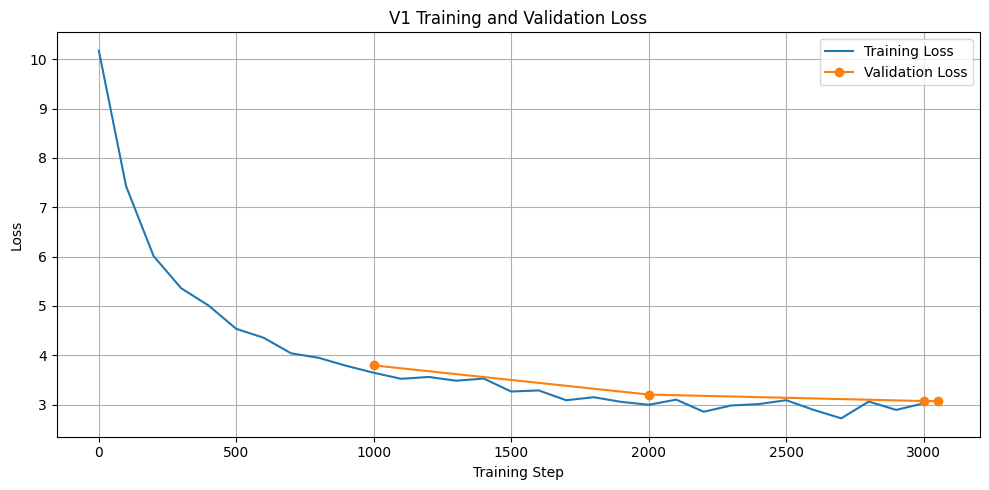

Saved: /kaggle/working/cs781_phase1_v1/v1_loss_curve.png


In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history["step"],
    history["train_loss"],
    label="Training Loss"
)

val_steps = [
    min(
        (i + 1) * EVAL_EVERY_STEPS,
        MAX_TRAIN_STEPS
    )
    for i in range(
        len(history["val_loss"])
    )
]

plt.plot(
    val_steps,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("V1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "v1_loss_curve.png"
)

plt.savefig(
    LOSS_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [34]:
import os
import json

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

final_model_path = os.path.join(
    MODEL_OUTPUT_DIR,
    "v1_model.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "config": {
            "vocab_size": tokenizer.vocab_size,
            "n_embd": N_EMBD,
            "n_layer": N_LAYER,
            "n_head": N_HEAD,
            "n_kv_head": N_KV_HEAD,
            "ffn_multiplier": FFN_MULTIPLIER,
            "dropout": DROPOUT,
            "context_length": MODEL_CONTEXT_LENGTH
        },
        "best_val_loss": best_val_loss,
        "best_val_perplexity": math.exp(best_val_loss)
    },
    final_model_path
)

print("Final V1 model saved to:")
print(final_model_path)

Final V1 model saved to:
/kaggle/working/cs781_phase1_v1/final_model/v1_model.pt


## 15. Push Model to Hugging Face Hub

In [35]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [36]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [37]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [38]:
# Load the best V1 model for test generation.

generation_model = V1LegalLM(
    vocab_size=tokenizer.vocab_size,
    n_embd=N_EMBD,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    ffn_multiplier=FFN_MULTIPLIER,
    dropout=DROPOUT
).to(DEVICE)

generation_model.load_state_dict(
    model.state_dict()
)

generation_model.eval()

generation_tokenizer = tokenizer

print("V1 generation model loaded.")
print("Device:", DEVICE)
print(
    f"Parameters: "
    f"{sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M"
)
print("KV cache is supported for generation.")

V1 generation model loaded.
Device: cuda
Parameters: 94.76M
KV cache is supported for generation.


## 19. Generate 128 Words
#### (words, not tokens)

In [39]:
# Generate legal-text continuations using the V1 model and KV cache.

def apply_repetition_penalty(logits, generated_tokens, penalty):
    if penalty == 1.0 or len(generated_tokens) == 0:
        return logits

    for token_id in set(generated_tokens):
        if logits[token_id] < 0:
            logits[token_id] *= penalty
        else:
            logits[token_id] /= penalty

    return logits


def sample_next_token(logits):
    logits = logits / max(TEMPERATURE, 1e-6)

    logits[PAD_TOKEN_ID] = float("-inf")
    logits[BOS_TOKEN_ID] = float("-inf")

    if TOP_K > 0:
        k = min(TOP_K, logits.numel())

        top_values, _ = torch.topk(
            logits,
            k
        )

        cutoff = top_values[-1]
        logits[logits < cutoff] = float("-inf")

    if TOP_P < 1.0:
        sorted_logits, sorted_indices = torch.sort(
            logits,
            descending=True
        )

        sorted_probs = torch.softmax(
            sorted_logits,
            dim=-1
        )

        cumulative_probs = torch.cumsum(
            sorted_probs,
            dim=-1
        )

        remove = cumulative_probs > TOP_P

        remove[1:] = remove[:-1].clone()
        remove[0] = False

        sorted_logits[remove] = float("-inf")

        logits = torch.full_like(
            logits,
            float("-inf")
        )

        logits.scatter_(
            0,
            sorted_indices,
            sorted_logits
        )

    probabilities = torch.softmax(
        logits,
        dim=-1
    )

    return torch.multinomial(
        probabilities,
        num_samples=1
    ).item()


def generate_one(
    prompt,
    model,
    tokenizer,
    device,
    target_words=128
):
    token_ids = tokenizer.encode(prompt)

    max_prompt_tokens = (
        MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
    )

    # Keep the most recent part of the prompt if it is too long.
    if len(token_ids) > max_prompt_tokens:
        token_ids = token_ids[-max_prompt_tokens:]

    input_ids = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    generated_tokens = []

    with torch.inference_mode():

        # First pass processes the complete prompt and builds the KV cache.
        logits, past_key_values = model(
            input_ids,
            use_cache=True
        )

        next_logits = logits[:, -1, :][0]

        while len(generated_tokens) < MAX_GENERATION_TOKENS:

            next_logits = apply_repetition_penalty(
                next_logits,
                generated_tokens,
                REPETITION_PENALTY
            )

            next_token = sample_next_token(
                next_logits.clone()
            )

            generated_tokens.append(
                next_token
            )

            generated_text = tokenizer.decode(
                generated_tokens
            )

            if len(generated_text.split()) >= target_words:
                break

            # Do not exceed the model context window.
            current_length = (
                len(token_ids)
                + len(generated_tokens)
            )

            if current_length >= MODEL_CONTEXT_LENGTH:
                break

            next_input = torch.tensor(
                [[next_token]],
                dtype=torch.long,
                device=device
            )

            logits, past_key_values = model(
                next_input,
                past_key_values=past_key_values,
                use_cache=True
            )

            next_logits = logits[:, -1, :][0]

    generated_text = tokenizer.decode(
        generated_tokens
    )

    generated_words = generated_text.split()

    return " ".join(
        generated_words[:target_words]
    )


def generate_batch(
    prompts,
    model,
    tokenizer,
    device,
    target_words=128
):
    predictions = []

    for prompt in prompts:
        prediction = generate_one(
            prompt=prompt,
            model=model,
            tokenizer=tokenizer,
            device=device,
            target_words=target_words
        )

        predictions.append(prediction)

    return predictions


print("Custom V1 generation functions ready.")
print("Generation uses the KV cache.")

Custom V1 generation functions ready.
Generation uses the KV cache.


## 20. Generate Predictions for the Test Set

In [40]:
# Generate predictions for the complete test set.

predictions = {}

GENERATION_BATCH_SIZE = 32

items = list(test_data.items())

total_examples = len(items)

print(
    f"Total test examples: {total_examples}"
)

for start in range(
    0,
    total_examples,
    GENERATION_BATCH_SIZE
):

    batch = items[
        start:start + GENERATION_BATCH_SIZE
    ]

    batch_ids = [
        str(example_id)
        for example_id, _ in batch
    ]

    batch_prompts = [
        record["text"]
        for _, record in batch
    ]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=DEVICE,
        target_words=128
    )

    for example_id, prediction in zip(
        batch_ids,
        batch_predictions
    ):

        predictions[example_id] = {
            "text": prediction
        }

    completed = start + len(batch)

    print(
        f"Completed {completed}/{total_examples} "
        f"({100 * completed / total_examples:.1f}%)"
    )

print("\nTest generation complete.")
print(
    f"Generated predictions: {len(predictions)}"
)

Total test examples: 1000
Completed 32/1000 (3.2%)
Completed 64/1000 (6.4%)
Completed 96/1000 (9.6%)
Completed 128/1000 (12.8%)
Completed 160/1000 (16.0%)
Completed 192/1000 (19.2%)
Completed 224/1000 (22.4%)
Completed 256/1000 (25.6%)
Completed 288/1000 (28.8%)
Completed 320/1000 (32.0%)
Completed 352/1000 (35.2%)
Completed 384/1000 (38.4%)
Completed 416/1000 (41.6%)
Completed 448/1000 (44.8%)
Completed 480/1000 (48.0%)
Completed 512/1000 (51.2%)
Completed 544/1000 (54.4%)
Completed 576/1000 (57.6%)
Completed 608/1000 (60.8%)
Completed 640/1000 (64.0%)
Completed 672/1000 (67.2%)
Completed 704/1000 (70.4%)
Completed 736/1000 (73.6%)
Completed 768/1000 (76.8%)
Completed 800/1000 (80.0%)
Completed 832/1000 (83.2%)
Completed 864/1000 (86.4%)
Completed 896/1000 (89.6%)
Completed 928/1000 (92.8%)
Completed 960/1000 (96.0%)
Completed 992/1000 (99.2%)
Completed 1000/1000 (100.0%)

Test generation complete.
Generated predictions: 1000


## 21. Save prediction.json

In [41]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1_v1/prediction.json


## 22. Create CodaBench Submission ZIP

In [42]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1_v1/submission.zip
